In [ ]:
# The purpose of this notebook is to figure out why for the 100,000 candidate formulas the predictions for density are clustering around .22

In [1]:
# get the experimental data

# import the data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
measured_se_cols = [
    "Avg_Density SE",
    "24h_se.1",
    "24h_se",
]

# Keep each target beside its standard error column
measured_cols = [
    col
    for target, se in zip(measured_target_cols, measured_se_cols)
    for col in (target, se)
]
df = df.loc[:, formula_cols + measured_cols]
df = df.rename(columns={
    "24h_se.1": "se_absorption",
    "24h_se": "se_retention",
})

print(df.head())

   TEM  Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0    8      NaN    NaN     NaN   NaN           0.192000        0.002667   
1    8      0.7    NaN     NaN   NaN           0.195000        0.007263   
2    8      1.0    NaN     NaN   NaN           0.159000        0.005033   
3    8      1.5    NaN     NaN   NaN           0.159933        0.004410   
4    8      2.0    NaN     NaN   NaN           0.201000        0.008817   

   24h_avg_pct absorption  se_absorption  24h_avg_pct_retention  se_retention  
0              113.616943       5.271375                  31.77          2.81  
1              103.817309       3.496766                  33.12          2.57  
2              129.464292       5.490086                  36.25          1.77  
3              120.749405       2.660519                  25.33          0.38  
4              113.871581       2.071998                  26.58          0.99  


In [2]:
# get the 100,000 candidate formulas, they are stored in candidate_set

# Formula constraints:
# - TEM: 5-8%.
# - Each chain extender (Joncryl, NC513, PEG-DE, NGDE): 0.7-3% when included; 0% when omitted.
# - Combined chain extender amount: no more than 6%.
# - Generate 100,000 valid candidate formulas.
import numpy as np
import pandas as pd

candidate_count = 100_000
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(10_000, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]
    extender_amounts = rng.uniform(0.7, 3.0, size=(batch_size, len(chain_extender_cols)))
    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 6.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(5.0, 8.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(5.0, 8.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(6.0).all()
for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    assert candidate_set.loc[active, col].between(0.7, 3.0).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 100,000 valid candidate formulas.
        TEM   Joncryl     NC513    PEG-DE      NGDE
0  7.498286  0.000000  0.000000  2.198651  0.000000
1  6.711942  1.784903  0.787018  1.213481  0.724965
2  5.505915  0.850501  1.969780  2.903304  0.000000
3  5.838431  2.472247  0.000000  1.159775  0.000000
4  5.735430  2.128875  0.000000  0.000000  0.791036
Maximum total chain extender: 5.999979539311976


In [3]:
# get predictions from the model for these formulas, they are stored in candidate_predictions

# load the gpr_models
import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")

# get predictions for these formulas from the GPR models

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
X_candidates = candidate_set.loc[:, feature_cols]

batch_size = 5_000
prediction_columns = {}

for name, model in gpr_models.items():
    batches = [
        model.predict(X_candidates.iloc[start : start + batch_size])
        for start in range(0, len(X_candidates), batch_size)
    ]
    prediction_columns[f"pred_{name}"] = np.concatenate(batches)

predictions = pd.DataFrame(prediction_columns, index=candidate_set.index)
candidate_predictions = pd.concat([candidate_set, predictions], axis=1)

display(candidate_predictions.head())


,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,pred_24h_avg_pct absorption,pred_24h_avg_pct_retention
0,7.498286,0.000000,0.000000,2.198651,0.000000,0.211892,263.930250,-1.427908
1,6.711942,1.784903,0.787018,1.213481,0.724965,0.214483,164.248133,28.815967
2,5.505915,0.850501,1.969780,2.903304,0.000000,0.232021,199.340182,35.024331
3,5.838431,2.472247,0.000000,1.159775,0.000000,0.215118,138.836635,29.186059
4,5.735430,2.128875,0.000000,0.000000,0.791036,0.215942,103.916927,27.661785


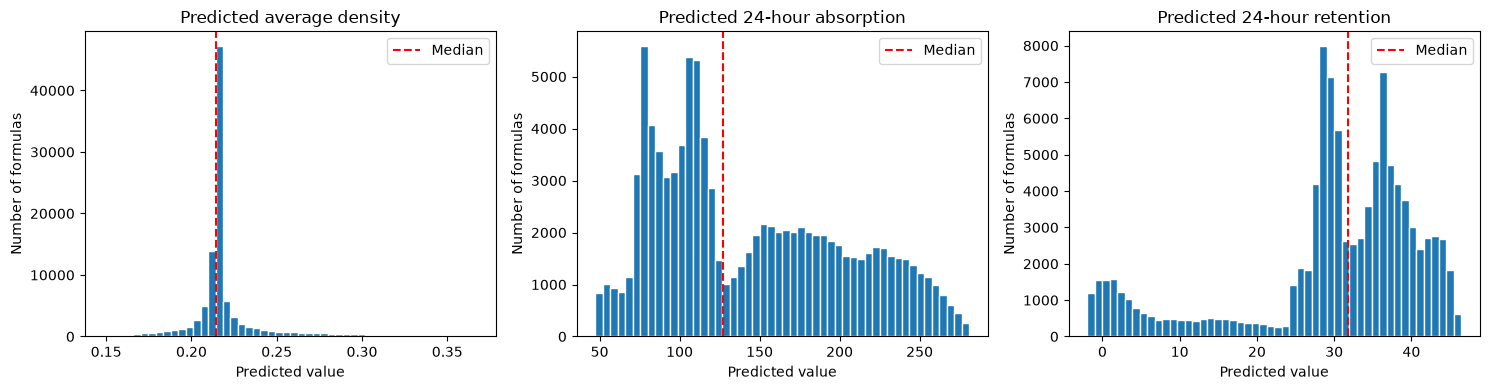

In [4]:
# get histograms of the predictions for the 3 properties for the 100,000 formulas in candidate set

import matplotlib.pyplot as plt

prediction_cols = [
    "pred_Avg_Density_g_cm3",
    "pred_24h_avg_pct absorption",
    "pred_24h_avg_pct_retention",
]

plot_titles = [
    "Predicted average density",
    "Predicted 24-hour absorption",
    "Predicted 24-hour retention",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, prediction_cols, plot_titles):
    values = candidate_predictions[col].dropna()
    ax.hist(values, bins=50, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Number of formulas")
    ax.axvline(values.median(), color="red", linestyle="--", label="Median")
    ax.legend()

fig.tight_layout()
plt.show()